# varD — root selection, quantile normalisation, spatial pseudotime

**Object:** `results/pt_variants/varD_keep_uninduced_no_efibouter/` — 40,217 cells.
Uninduced **kept** (8,326 cells); `efib_outer` and annotated `decidual_apoptotic` dropped; **no** mature
score-trim (the AUCell audit showed score-flagged matures are gene-set-dependent, so the mature tail is
handled by normalisation here instead of by deletion).

**Run on a compute node** (`--mem 200G --cpus-per-task 8`): §6 runs Palantir on 40k cells.

## Two things this notebook exists to get right

1. **Palantir 1.4.5 ignores `early_cell` by default.** `use_early_cell_as_start=False` is the default, and
   with it off the pseudotime minimum lands on some *other* cell — measured 2026-09-02: three different
   roots gave `pt[root]` = 0.346 / 0.270 / 0.125 and none of them was the argmin. §6 passes
   `use_early_cell_as_start=True` and **asserts `pt[root] == 0`**. Any earlier Palantir "manual root"
   result that did not pass this flag was not rooted where its provenance string claims.
2. **Diffusion-component signs are arbitrary and differ per object** (each variant got its own scVI
   retrain). §2 measures which DC and which end is the *early* end instead of assuming — for varD,
   `spearman(DC1, subtype rank) = -0.818`, so the **maximum** of DC1 is the fibroblast pole.

Nothing here modifies any h5ad. Outputs are CSVs under `results/pt_variants/manual_roots/`.

In [1]:
import pathlib, json, h5py, warnings
import numpy as np, pandas as pd, scanpy as sc, anndata as ad
import matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import spearmanr
warnings.filterwarnings("ignore")
try:    from anndata.io import read_elem
except ImportError: from anndata.experimental import read_elem

X    = pathlib.Path("/n/lab_storage/eddy_lab/users/nhilgert/xmens_final")
VARD = X/"results/pt_variants/varD_keep_uninduced_no_efibouter/varD_keep_uninduced_no_efibouter_embedded.h5ad"
QC   = X/"data/interim/qc_spatial_mouse.h5ad"          # 04f: 5 plain MADs + 10 boxes + tissue_section
ISO  = X/"results/isodepth/mouse_fibdec_isodepth.h5ad" # for the isodepth comparison in §10
OUT  = X/"results/pt_variants/manual_roots"; OUT.mkdir(parents=True, exist_ok=True)

SUBORDER = ["efib_proliferative","efib_outer","efib_middle","efib_middle_induced",
            "efib_subluminal","decidual_boundary","decidual_proliferative","decidual_mature"]
TPORDER  = ["uninduced","1_dpi_early","1_dpi_late","2_dpi","3_dpi","4_dpi_bleeding"]
RANK   = {s:i for i,s in enumerate(SUBORDER)}
TPRANK = {t:i for i,t in enumerate(TPORDER)}
PAL    = dict(zip(SUBORDER, sns.color_palette("viridis", len(SUBORDER))))
TPAL   = dict(zip(TPORDER,  sns.color_palette("rocket_r", len(TPORDER))))

CHECKS = []
def verify(label, got, want=True, note=""):
    ok = bool(got) if isinstance(want, bool) else (got == want)
    CHECKS.append((label, ok, got, note))
    print(("PASS  " if ok else "FAIL  ") + label + f"   [{got}]" + (f"  {note}" if note else ""))
    return ok
sc.settings.verbosity = 1

## 1 — load varD, and join the **current** QC'd coordinates + `tissue_section`

varD carries `x_um_qc` from before the 2026-09-02 spatial-QC change, so those are stale. Everything spatial below is joined fresh from the 04f output by barcode (100% join, verified).

In [2]:
with h5py.File(VARD, "r") as f:
    A = ad.AnnData(obs=read_elem(f["obs"]))
    for k in ("X_diffmap","X_scVI","X_umap"): A.obsm[k] = np.asarray(read_elem(f[f"obsm/{k}"]), float)
    for k in ("connectivities","distances"):
        if k in f["obsp"]: A.obsp[k] = read_elem(f[f"obsp/{k}"])
    for k in ("neighbors","diffmap_evals"):
        if k in f["uns"]: A.uns[k] = read_elem(f[f"uns/{k}"])
O = A.obs
for c in ("cell_subtype","timepoint","sample"): O[c] = O[c].astype(str)

# stale coordinate columns from the object: drop them so nothing downstream can read them by accident
O = O.drop(columns=[c for c in ("x_um_qc","y_um_qc","x_um_dbscan","y_um_dbscan","spatial_qc_reason") if c in O.columns])

with h5py.File(QC, "r") as f:
    q = pd.DataFrame({k: read_elem(f[f"obs/{k}"]) for k in
                      ("x_um_qc","y_um_qc","spatial_qc_reason","tissue_section")},
                     index=pd.Index(read_elem(f["obs/_index"])))
q["spatial_qc_reason"] = q.spatial_qc_reason.astype(str); q["tissue_section"] = q.tissue_section.astype(object)
J = q.reindex(O.index)
O["x_um"] = pd.to_numeric(J.x_um_qc, errors="coerce").to_numpy(float)
O["y_um"] = pd.to_numeric(J.y_um_qc, errors="coerce").to_numpy(float)
O["spatial_qc_reason"] = J.spatial_qc_reason.to_numpy()
O["tissue_section"]    = J.tissue_section.to_numpy()
A.obs = O
DM = A.obsm["X_diffmap"]; NDC = DM.shape[1] - 1     # column 0 is the trivial eigenvector

print(f"varD {A.n_obs:,} cells | X_diffmap {DM.shape} -> DC1..DC{NDC} = columns 1..{NDC}")
print("subtypes:", O.cell_subtype.value_counts().to_dict())
verify("every varD barcode found in the 04f QC output", int(O.index.isin(q.index).sum()), A.n_obs)
verify("cells with a QC'd coordinate", int(np.isfinite(O.x_um).sum()) > 0,
       note=f"{int(np.isfinite(O.x_um).sum()):,} of {A.n_obs:,}; sections={O.tissue_section.dropna().nunique()}")
verify("efib_outer and decidual_apoptotic are absent",
       not {"efib_outer","decidual_apoptotic"} & set(O.cell_subtype.unique()))

varD 40,217 cells | X_diffmap (40217, 15) -> DC1..DC14 = columns 1..14
subtypes: {'decidual_proliferative': 14434, 'efib_middle_induced': 8775, 'efib_middle': 4764, 'efib_subluminal': 3886, 'decidual_mature': 3856, 'decidual_boundary': 3722, 'efib_proliferative': 780}
PASS  every varD barcode found in the 04f QC output   [40217]
PASS  cells with a QC'd coordinate   [True]  22,191 of 40,217; sections=11
PASS  efib_outer and decidual_apoptotic are absent   [True]


True

## 2 — which DC, and which end, is the **early** end?

Don't assume. `spearman(DC_k, subtype trajectory rank)` is negative when the component runs backwards relative to `SUBORDER`, so a negative value means the **maximum** of that DC is the early (fibroblast) pole. The tail table shows what actually sits at each end.

In [3]:
rank_sub = O.cell_subtype.map(RANK).to_numpy(float)
rows = []
for k in range(1, NDC+1):
    v = DM[:, k]
    lo, hi = np.percentile(v, 2), np.percentile(v, 98)
    def top(mask, col, n=2):
        s = O.loc[mask, col].value_counts(normalize=True)
        return ", ".join(f"{i} {100*x:.0f}%" for i, x in s.head(n).items())
    rows.append(dict(DC=f"DC{k}",
        rho_subtype_rank=round(float(spearmanr(v, rank_sub).statistic), 3),
        early_end=("max" if spearmanr(v, rank_sub).statistic < 0 else "min"),
        low_tail_subtype=top(v <= lo, "cell_subtype"), low_tail_tp=top(v <= lo, "timepoint"),
        high_tail_subtype=top(v >= hi, "cell_subtype"), high_tail_tp=top(v >= hi, "timepoint")))
ORIENT = pd.DataFrame(rows).set_index("DC")
display(ORIENT[["rho_subtype_rank","early_end","low_tail_subtype","high_tail_subtype"]])
display(ORIENT[["low_tail_tp","high_tail_tp"]])

best = ORIENT.rho_subtype_rank.abs().idxmax()
print(f"\nstrongest differentiation axis: {best} (|rho| = {ORIENT.loc[best,'rho_subtype_rank']:+.3f}), "
      f"early end = {ORIENT.loc[best,'early_end']}")
verify("DC1 runs backwards vs SUBORDER, so DC1 max is the early end",
       ORIENT.loc["DC1","rho_subtype_rank"] < 0, note="measured 2026-09-02: rho = -0.818")

,rho_subtype_rank,early_end,low_tail_subtype,high_tail_subtype
DC,,,,
DC1,-0.818,max,"decidual_mature 100%, efib_middle 0%","efib_subluminal 58%, efib_middle_induced 41%"
DC2,-0.558,max,"decidual_proliferative 99%, decidual_mature 1%","decidual_mature 100%, efib_subluminal 0%"
DC3,0.219,min,"decidual_mature 97%, decidual_proliferative 3%","decidual_mature 51%, decidual_proliferative 36%"
DC4,-0.123,max,"efib_subluminal 70%, decidual_mature 29%","decidual_mature 46%, efib_middle_induced 34%"
DC5,0.290,min,"decidual_proliferative 94%, decidual_mature 5%","decidual_mature 69%, decidual_proliferative 18%"
DC6,-0.192,max,"decidual_mature 49%, decidual_proliferative 33%","decidual_mature 61%, decidual_proliferative 38%"
DC7,-0.149,max,"decidual_mature 47%, efib_subluminal 28%","decidual_proliferative 46%, decidual_mature 39%"
DC8,0.167,min,"decidual_mature 52%, efib_middle 38%","efib_middle_induced 48%, efib_subluminal 29%"
DC9,0.056,min,"decidual_proliferative 54%, decidual_mature 44%","decidual_proliferative 63%, decidual_mature 32%"


,low_tail_tp,high_tail_tp
DC,,
DC1,"3_dpi 70%, 4_dpi_bleeding 29%","uninduced 34%, 1_dpi_late 32%"
DC2,"4_dpi_bleeding 58%, 3_dpi 41%","3_dpi 70%, 4_dpi_bleeding 24%"
DC3,"4_dpi_bleeding 61%, 3_dpi 39%","3_dpi 57%, 1_dpi_late 23%"
DC4,"uninduced 67%, 4_dpi_bleeding 20%","3_dpi 53%, 4_dpi_bleeding 44%"
DC5,"3_dpi 56%, 4_dpi_bleeding 44%","1_dpi_late 68%, 2_dpi 13%"
DC6,"3_dpi 32%, 1_dpi_late 25%","4_dpi_bleeding 42%, 3_dpi 38%"
DC7,"3_dpi 47%, uninduced 31%","3_dpi 40%, 1_dpi_late 32%"
DC8,"1_dpi_late 41%, uninduced 40%","4_dpi_bleeding 55%, 1_dpi_early 18%"
DC9,"3_dpi 45%, 1_dpi_late 23%","4_dpi_bleeding 76%, 1_dpi_late 20%"



strongest differentiation axis: DC1 (|rho| = -0.818), early end = max
PASS  DC1 runs backwards vs SUBORDER, so DC1 max is the early end   [True]  measured 2026-09-02: rho = -0.818


True

## 3 — DC panels

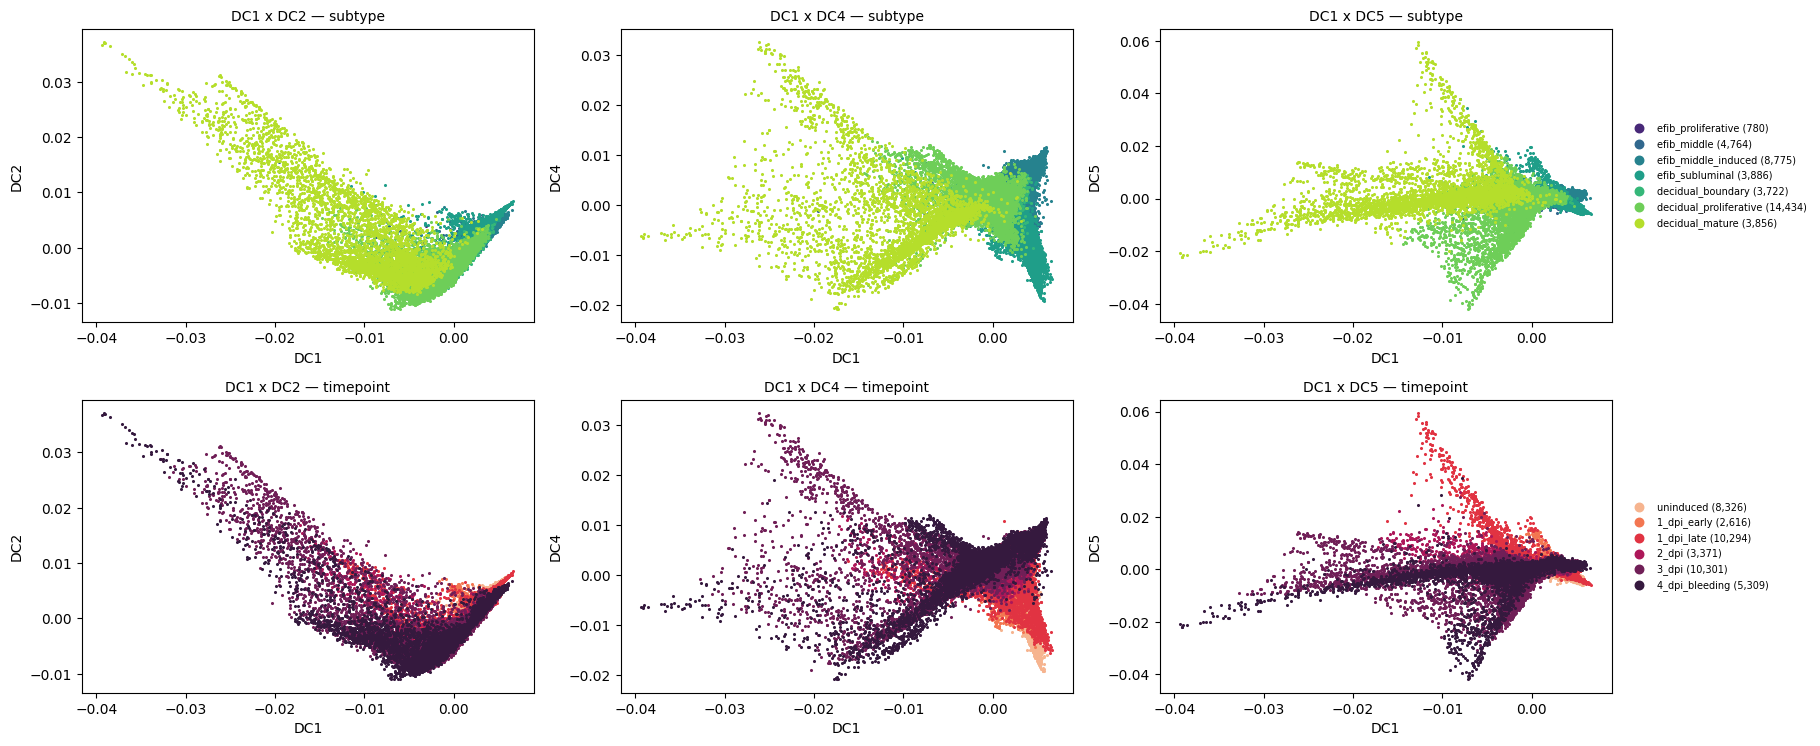

In [4]:
def dc_panels(pairs=((1,2),(1,4),(1,5)), mark=None, figsize=6.1):
    fig, axes = plt.subplots(2, len(pairs), figsize=(figsize*len(pairs), 2*figsize*0.62), squeeze=False)
    for j,(a,b) in enumerate(pairs):
        for i,(cmap_,col,ttl) in enumerate(((PAL,"cell_subtype","subtype"),(TPAL,"timepoint","timepoint"))):
            ax = axes[i][j]; order = [s for s in (SUBORDER if col=="cell_subtype" else TPORDER)
                                      if s in set(O[col])]
            for cat in order:
                m = (O[col] == cat).to_numpy()
                ax.scatter(DM[m,a], DM[m,b], s=1.5, c=[cmap_[cat]], label=f"{cat} ({m.sum():,})", rasterized=True)
            if mark is not None:
                for bc, mk, cl in mark:
                    p = O.index.get_loc(bc)
                    ax.scatter(DM[p,a], DM[p,b], s=170, marker=mk, c=cl, edgecolor="k", lw=0.9, zorder=6)
            ax.set_xlabel(f"DC{a}"); ax.set_ylabel(f"DC{b}"); ax.set_title(f"DC{a} x DC{b} — {ttl}", fontsize=10)
            if j == len(pairs)-1:
                ax.legend(fontsize=7, markerscale=5, loc="center left", bbox_to_anchor=(1.02,0.5), frameon=False)
    fig.tight_layout(); return fig

_ = dc_panels()

## 4 — browse every root choice

`candidates(...)` scores one filter; `root_grid(...)` sweeps **every subtype × timepoint** so you can see all the options at once. `pct=0` takes the single most extreme cell — fragile, and how the earlier `anchor_far` root misfired; `pct=2` takes the cell nearest the 2nd/98th percentile of the filtered pool.

In [5]:
def _resolve(dc=1, side="max", pct=2, subtype=None, timepoint=None):
    m = np.ones(len(O), bool)
    if subtype   is not None: m &= (O.cell_subtype == subtype).to_numpy()
    if timepoint is not None: m &= (O.timepoint == timepoint).to_numpy()
    if not m.any(): return None
    v = DM[m, dc]
    if pct == 0: j = int(np.argmax(v)) if side == "max" else int(np.argmin(v))
    else:
        q = np.percentile(v, 100-pct if side == "max" else pct)
        j = int(np.argmin(np.abs(v - q)))
    idx = int(np.flatnonzero(m)[j])
    return O.index[idx], idx, int(m.sum())

def candidates(dc=1, side="max", pct=2, subtype=None, timepoint=None):
    r = _resolve(dc, side, pct, subtype, timepoint)
    if r is None: return None
    bc, idx, npool = r
    return dict(barcode=bc, idx=idx, pool=npool, subtype=O.cell_subtype.iloc[idx],
                timepoint=O.timepoint.iloc[idx], sample=O["sample"].iloc[idx],
                DCval=round(float(DM[idx,dc]),6),
                DC_global_pct=round(float((DM[:,dc] < DM[idx,dc]).mean()),4),
                has_coords=bool(np.isfinite(O.x_um.iloc[idx])),
                section=O.tissue_section.iloc[idx])

def root_grid(dc=1, side="max", pct=2, min_pool=50):
    out = []
    for s in [x for x in SUBORDER if x in set(O.cell_subtype)]:
        for t in [x for x in TPORDER if x in set(O.timepoint)]:
            c = candidates(dc, side, pct, subtype=s, timepoint=t)
            if c and c["pool"] >= min_pool:
                out.append(dict(subtype=s, timepoint=t, pool=c["pool"], barcode=c["barcode"],
                                DC_global_pct=c["DC_global_pct"], has_coords=c["has_coords"]))
    G = pd.DataFrame(out).sort_values("DC_global_pct", ascending=(side=="min"))
    return G.reset_index(drop=True)

G = root_grid(dc=1, side="max", pct=2)
print("Every subtype x timepoint option, ordered by how extreme the DC1 value is")
print("(DC_global_pct near 1.00 = deepest into the fibroblast pole):")
display(G.head(25))

Every subtype x timepoint option, ordered by how extreme the DC1 value is
(DC_global_pct near 1.00 = deepest into the fibroblast pole):


,subtype,timepoint,pool,barcode,DC_global_pct,has_coords
0,efib_subluminal,1_dpi_late,724,GAGTGAGAGCAACAGC-1-1_dpi_late_mck12b,0.9996,False
1,efib_middle_induced,4_dpi_bleeding,1086,GGTTAACGTGGCCCAT-1-4_dpi_bleeding_mck11a,0.9984,False
2,efib_subluminal,uninduced,2789,CTCTGGTAGCTTCTAG-1-uninduced_mck8b,0.9926,False
3,efib_middle_induced,1_dpi_late,3734,CCTCCAAAGTCCCGAC-1-1_dpi_late_mck12b,0.9765,True
4,efib_middle_induced,3_dpi,1522,TCATGTTTCATTCTTG-1-3_dpi_mck10a,0.9718,False
5,efib_middle_induced,2_dpi,920,CTCCCAAGTGAGATCG-1-2_dpi_mck15,0.9618,True
6,efib_middle,1_dpi_late,152,GCCATTCTCTGCATAG-1-1_dpi_late_mck12b,0.9563,False
7,efib_middle,uninduced,4429,CCTCACATCTGAGAAA-1-uninduced_mck8a,0.9440,True
8,efib_middle_induced,1_dpi_early,902,GATTTCTAGCCTCGTG-1-1_dpi_early_mck1,0.9380,True
9,efib_middle,2_dpi,69,GGCTTTCCACACAGAG-1-2_dpi_mck15,0.9071,True


### Unfiltered and single-subtype shortcuts

In [6]:
short = {}
for lbl, kw in {
    "global max (no filter)":            dict(pct=0),
    "uninduced, any subtype":            dict(timepoint="uninduced"),
    "uninduced + efib_middle":           dict(timepoint="uninduced", subtype="efib_middle"),
    "uninduced + efib_subluminal":       dict(timepoint="uninduced", subtype="efib_subluminal"),
    "uninduced + efib_proliferative":    dict(timepoint="uninduced", subtype="efib_proliferative"),
    "efib_middle, any timepoint":        dict(subtype="efib_middle"),
}.items():
    c = candidates(dc=1, side="max", **kw)
    if c: short[lbl] = c
S = pd.DataFrame(short).T[["subtype","timepoint","sample","pool","DC_global_pct","has_coords","barcode"]]
display(S)

,subtype,timepoint,sample,pool,DC_global_pct,has_coords,barcode
global max (no filter),efib_subluminal,1_dpi_late,1_dpi_late_mck12b,40217,1.0,False,TGGTTAGCAGACCCGT-1-1_dpi_late_mck12b
"uninduced, any subtype",efib_subluminal,uninduced,uninduced_mck8a,8326,0.986,False,GAGGGTAGTCGTATGT-1-uninduced_mck8a
uninduced + efib_middle,efib_middle,uninduced,uninduced_mck8a,4429,0.944,True,CCTCACATCTGAGAAA-1-uninduced_mck8a
uninduced + efib_subluminal,efib_subluminal,uninduced,uninduced_mck8b,2789,0.9926,False,CTCTGGTAGCTTCTAG-1-uninduced_mck8b
uninduced + efib_proliferative,efib_proliferative,uninduced,uninduced_mck8a,434,0.8556,False,TCGCAGGAGCTCCACG-1-uninduced_mck8a
"efib_middle, any timepoint",efib_middle,uninduced,uninduced_mck8a,4764,0.9437,False,GGTGGCTAGCAGTACG-1-uninduced_mck8a


## 5 — **choose the root** (edit this cell)

Either set `ROOT` as a filter spec, or set `ROOT_BARCODE` to a literal barcode from the tables above (a barcode overrides the spec).

root: GTTAGTGTCACAAGAA-1-uninduced_mck8a
  {'dc': 1, 'side': 'max', 'pct': 0, 'timepoint': 'uninduced'} -> pool 8326
  subtype=efib_subluminal  timepoint=uninduced  sample=uninduced_mck8a  section=uninduced_mck8a__A
  DC1=0.0060167  global DC1 percentile=0.9994
PASS  root sits at the early end of DC1 (global percentile > 0.9)   [True]  if this FAILS the trajectory will run backwards and the gate in section 8 will refuse it


True

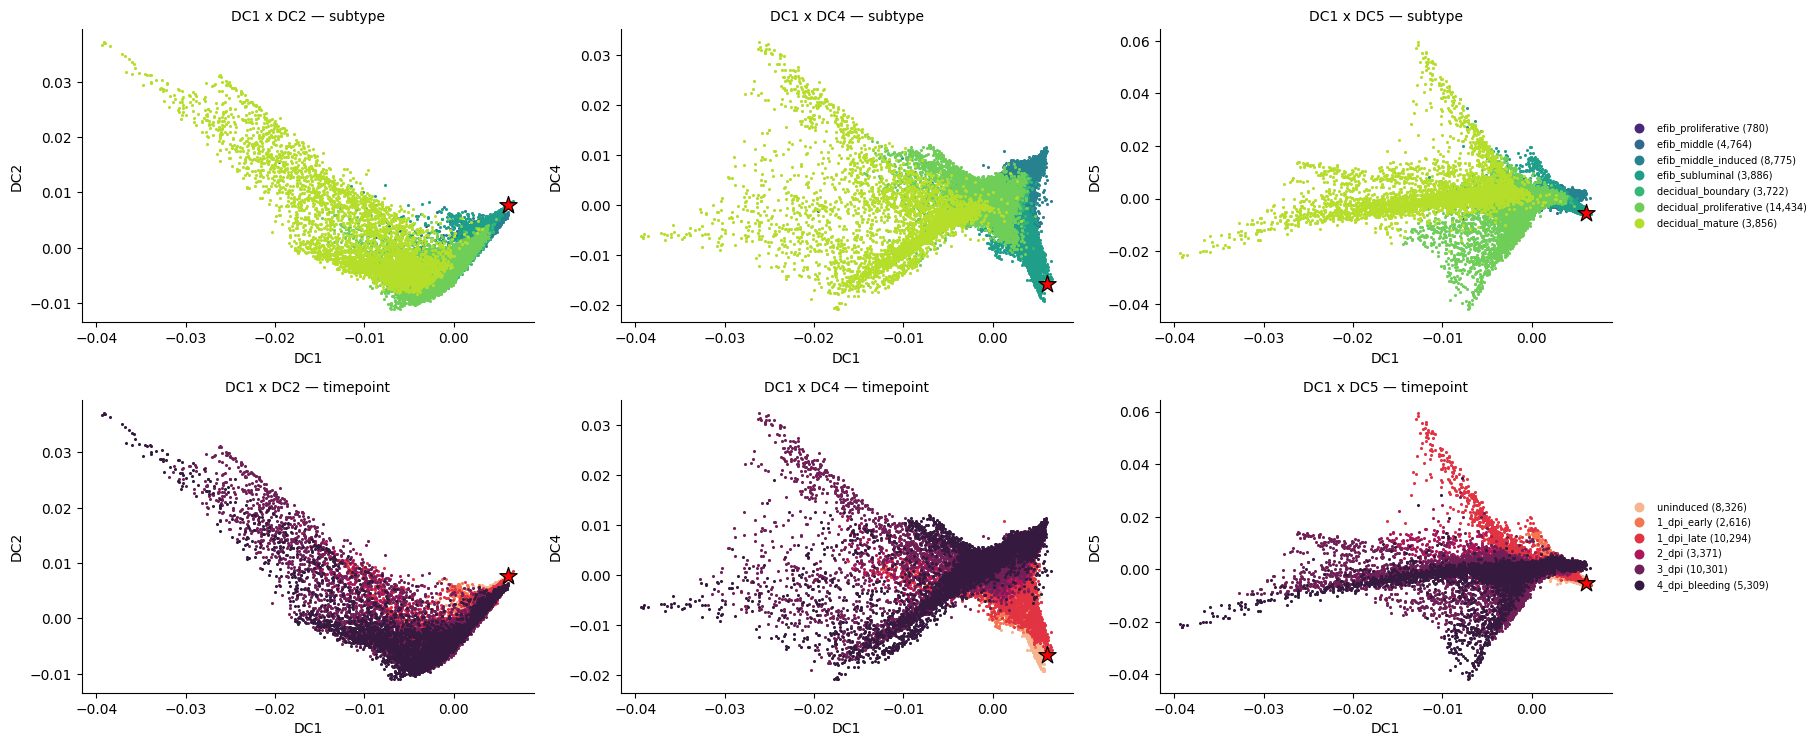

In [26]:
ROOT = dict(dc=1, side="max", pct=0, timepoint="uninduced", subtype="efib_middle")
ROOT = dict(dc=1, side="max", pct=0, timepoint="uninduced")
#ROOT = dict(dc=1, side="max", pct=0)          # -> TGGTTAGCAGACCCGT-1-1_dpi_late_mck12b (efib_subluminal, 1_dpi_late)
ROOT_BARCODE = None      # e.g. "CCTCACATCTGAGAAA-1-uninduced_mck8a" — overrides ROOT when set

if ROOT_BARCODE:
    assert ROOT_BARCODE in O.index, f"{ROOT_BARCODE} not in varD"
    ROOT_BC, ROOT_IDX = ROOT_BARCODE, int(O.index.get_loc(ROOT_BARCODE))
    ROOT_DESC = f"explicit barcode {ROOT_BARCODE}"
else:
    ROOT_BC, ROOT_IDX, npool = _resolve(**ROOT)
    ROOT_DESC = f"{ROOT} -> pool {npool}"
print(f"root: {ROOT_BC}\n  {ROOT_DESC}")
print(f"  subtype={O.cell_subtype.iloc[ROOT_IDX]}  timepoint={O.timepoint.iloc[ROOT_IDX]}  "
      f"sample={O['sample'].iloc[ROOT_IDX]}  section={O.tissue_section.iloc[ROOT_IDX]}")
print(f"  DC1={DM[ROOT_IDX,1]:.6g}  global DC1 percentile={float((DM[:,1] < DM[ROOT_IDX,1]).mean()):.4f}")

_ = dc_panels(mark=[(ROOT_BC, "*", "red")])
verify("root sits at the early end of DC1 (global percentile > 0.9)",
       float((DM[:,1] < DM[ROOT_IDX,1]).mean()) > 0.9,
       note="if this FAILS the trajectory will run backwards and the gate in section 8 will refuse it")

## 6 — pseudotime from that root

DPT on the stored diffusion map, Palantir on `X_scVI`. **`use_early_cell_as_start=True` is mandatory** — see the header. Both are asserted to be zero at the chosen root.

In [27]:
import palantir
res = pd.DataFrame(index=O.index); res.index.name = "cell"
for c in ("cell_subtype","timepoint","sample","tissue_section","x_um","y_um","spatial_qc_reason"):
    res[c] = O[c].to_numpy()
res["DC1"] = DM[:,1]

A.uns["iroot"] = ROOT_IDX
sc.tl.dpt(A, n_dcs=min(10, DM.shape[1]))
res["dpt"] = A.obs["dpt_pseudotime"].to_numpy(float)
verify("DPT is zero at the chosen root", float(res.dpt.iloc[ROOT_IDX]) == 0.0)

ms_df = pd.DataFrame(A.obsm["X_scVI"], index=O.index)
dmap  = palantir.utils.run_diffusion_maps(ms_df, n_components=10, knn=30)
ms    = palantir.utils.determine_multiscale_space(dmap)
pr    = palantir.core.run_palantir(ms, ROOT_BC, num_waypoints=1200, n_jobs=8,
                                   use_early_cell_as_start=True, seed=0)   # <- do not drop this flag
res["palantir"] = pr.pseudotime.reindex(O.index).to_numpy(float)
verify("Palantir is zero at the chosen root (i.e. the root was honoured)",
       float(res.palantir.iloc[ROOT_IDX]) == 0.0,
       note="False here means use_early_cell_as_start was ignored and Palantir re-picked its own start")
verify("Palantir's minimum IS the chosen root", res.palantir.idxmin() == ROOT_BC)
print("\nspearman(DPT, Palantir) =", round(float(spearmanr(res.dpt, res.palantir).statistic), 4))
res[["dpt","palantir"]].describe().round(4)

PASS  DPT is zero at the chosen root   [True]
Sampling and flocking waypoints...
Time for determining waypoints: 0.0003994186719258626 minutes
Determining pseudotime...
Shortest path distances using 30-nearest neighbor graph...
Time for shortest paths: 0.3411349574724833 minutes
Iteratively refining the pseudotime...
Correlation at iteration 1: 0.9999
Correlation at iteration 2: 1.0000
Entropy and branch probabilities...
Markov chain construction...
Identification of terminal states...
Computing fundamental matrix and absorption probabilities...
Project results to all cells...
PASS  Palantir is zero at the chosen root (i.e. the root was honoured)   [True]  False here means use_early_cell_as_start was ignored and Palantir re-picked its own start
PASS  Palantir's minimum IS the chosen root   [True]

spearman(DPT, Palantir) = 0.815


,dpt,palantir
count,40217.0000,40217.0000
mean,0.1990,0.1831
std,0.0686,0.1356
min,0.0000,0.0000
25%,0.1652,0.0713
50%,0.1987,0.1700
75%,0.2218,0.2595
max,1.0000,1.0000


## 7 — quantile normalisation

`*_q` is the continuous quantile transform: each cell's percentile among all cells (`rank(pct=True)`), uniform on (0,1]. **Rank statistics are identical** to the raw pseudotime — only the spacing changes, which is the point: it removes the long compressed decidual tail without deleting cells.

`*_qsec` / `*_qtp` normalise *within* each tissue section / timepoint. Those remove between-group shifts, so use them only for comparing trajectory **shape** across sections — never to claim a section or day is further along, since by construction every group then spans the same range.

PASS  quantile transform preserves the ordering exactly   [True]

median by subtype (Palantir):


,raw,quantile
cell_subtype,,
efib_proliferative,0.148,0.460
efib_middle,0.071,0.251
efib_middle_induced,0.067,0.225
efib_subluminal,0.045,0.094
decidual_boundary,0.192,0.542
decidual_proliferative,0.248,0.723
decidual_mature,0.392,0.947


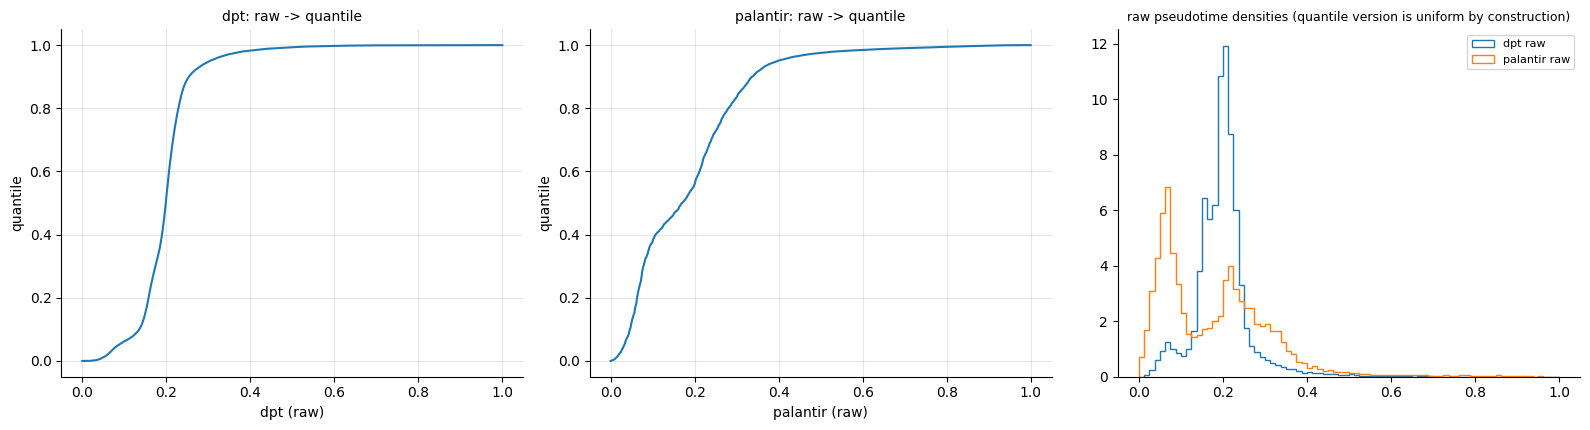

In [28]:
for m in ("dpt","palantir"):
    res[f"{m}_q"]    = res[m].rank(pct=True)
    res[f"{m}_qsec"] = res.groupby("tissue_section", observed=True)[m].rank(pct=True)
    res[f"{m}_qtp"]  = res.groupby("timepoint",      observed=True)[m].rank(pct=True)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, m in zip(axes[:2], ("dpt","palantir")):
    ax.plot(np.sort(res[m]), np.linspace(0,1,len(res)), lw=1.5)
    ax.set_xlabel(f"{m} (raw)"); ax.set_ylabel("quantile"); ax.set_title(f"{m}: raw -> quantile", fontsize=10)
    ax.grid(alpha=.3)
for m, c in (("dpt","C0"), ("palantir","C1")):
    axes[2].hist(res[m], bins=80, histtype="step", density=True, label=f"{m} raw", color=c)
axes[2].legend(fontsize=8); axes[2].set_title("raw pseudotime densities (quantile version is uniform by construction)", fontsize=9)
fig.tight_layout()

verify("quantile transform preserves the ordering exactly",
       float(spearmanr(res.palantir, res.palantir_q).statistic) == 1.0)
print("\nmedian by subtype (Palantir):")
display(pd.DataFrame({"raw": res.groupby("cell_subtype").palantir.median(),
                      "quantile": res.groupby("cell_subtype").palantir_q.median()}
                     ).reindex([s for s in SUBORDER if s in set(O.cell_subtype)]).round(3))

## 8 — orientation gates

A failing gate is reported as **REFUSED** and the pseudotime is *not* flipped — pick a different root instead. `rho_timepoint` pooled over all cells is confounded by composition (later sections are mostly decidual), so the decidual-compartment-only version is the one to read.

In [29]:
def gates(pt):
    sr = O.cell_subtype.map(RANK).to_numpy(float); tr = O.timepoint.map(TPRANK).to_numpy(float)
    ok = np.isfinite(pt)
    r_sub = float(spearmanr(pt[ok], sr[ok]).statistic)
    m2 = ok & np.isfinite(tr); r_tp = float(spearmanr(pt[m2], tr[m2]).statistic)
    dec = m2 & O.cell_subtype.str.startswith("decidual").to_numpy()
    fib = m2 & O.cell_subtype.str.startswith("efib").to_numpy()
    r_dec = float(spearmanr(pt[dec], tr[dec]).statistic)
    r_fib = float(spearmanr(pt[fib], tr[fib]).statistic)
    return dict(rho_subtype_rank=round(r_sub,4), rho_day_pooled=round(r_tp,4),
                rho_day_decidual_only=round(r_dec,4), rho_day_fibroblast_only=round(r_fib,4),
                verdict="OK" if (r_sub > 0 and r_dec > 0) else "REFUSED (not flipped — choose another root)")
GATES = {m: gates(res[m].to_numpy()) for m in ("dpt","palantir")}
display(pd.DataFrame(GATES).T)
for m, g in GATES.items(): verify(f"{m}: orientation gate", g["verdict"] == "OK", note=g["verdict"])

,rho_subtype_rank,rho_day_pooled,rho_day_decidual_only,rho_day_fibroblast_only,verdict
dpt,0.721,0.7478,0.4708,0.7118,OK
palantir,0.8121,0.5845,0.4314,0.0523,OK


PASS  dpt: orientation gate   [True]  OK
PASS  palantir: orientation gate   [True]  OK


## 9 — violins: raw vs quantile

median by timepoint, split by compartment (Palantir quantile) — the pooled column is composition-driven:


compartment,decidual,fibroblast
timepoint,,
uninduced,0.395,0.224
1_dpi_early,0.540,0.331
1_dpi_late,0.633,0.172
2_dpi,0.679,0.273
3_dpi,0.788,0.314
4_dpi_bleeding,0.819,0.116


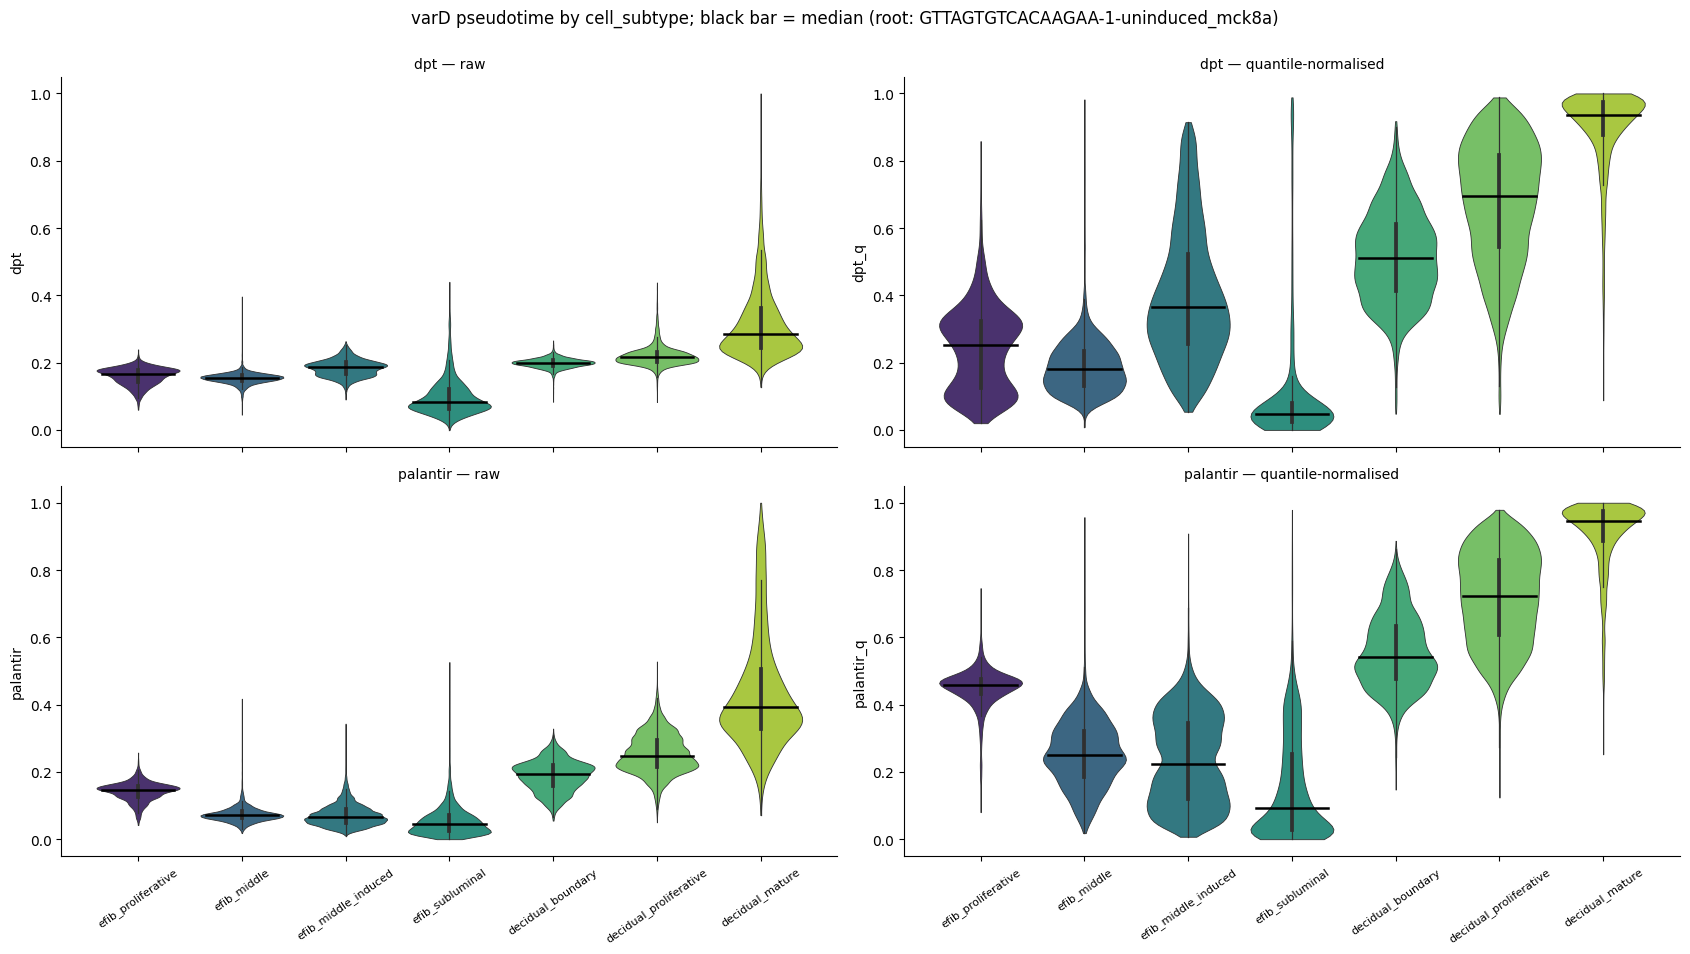

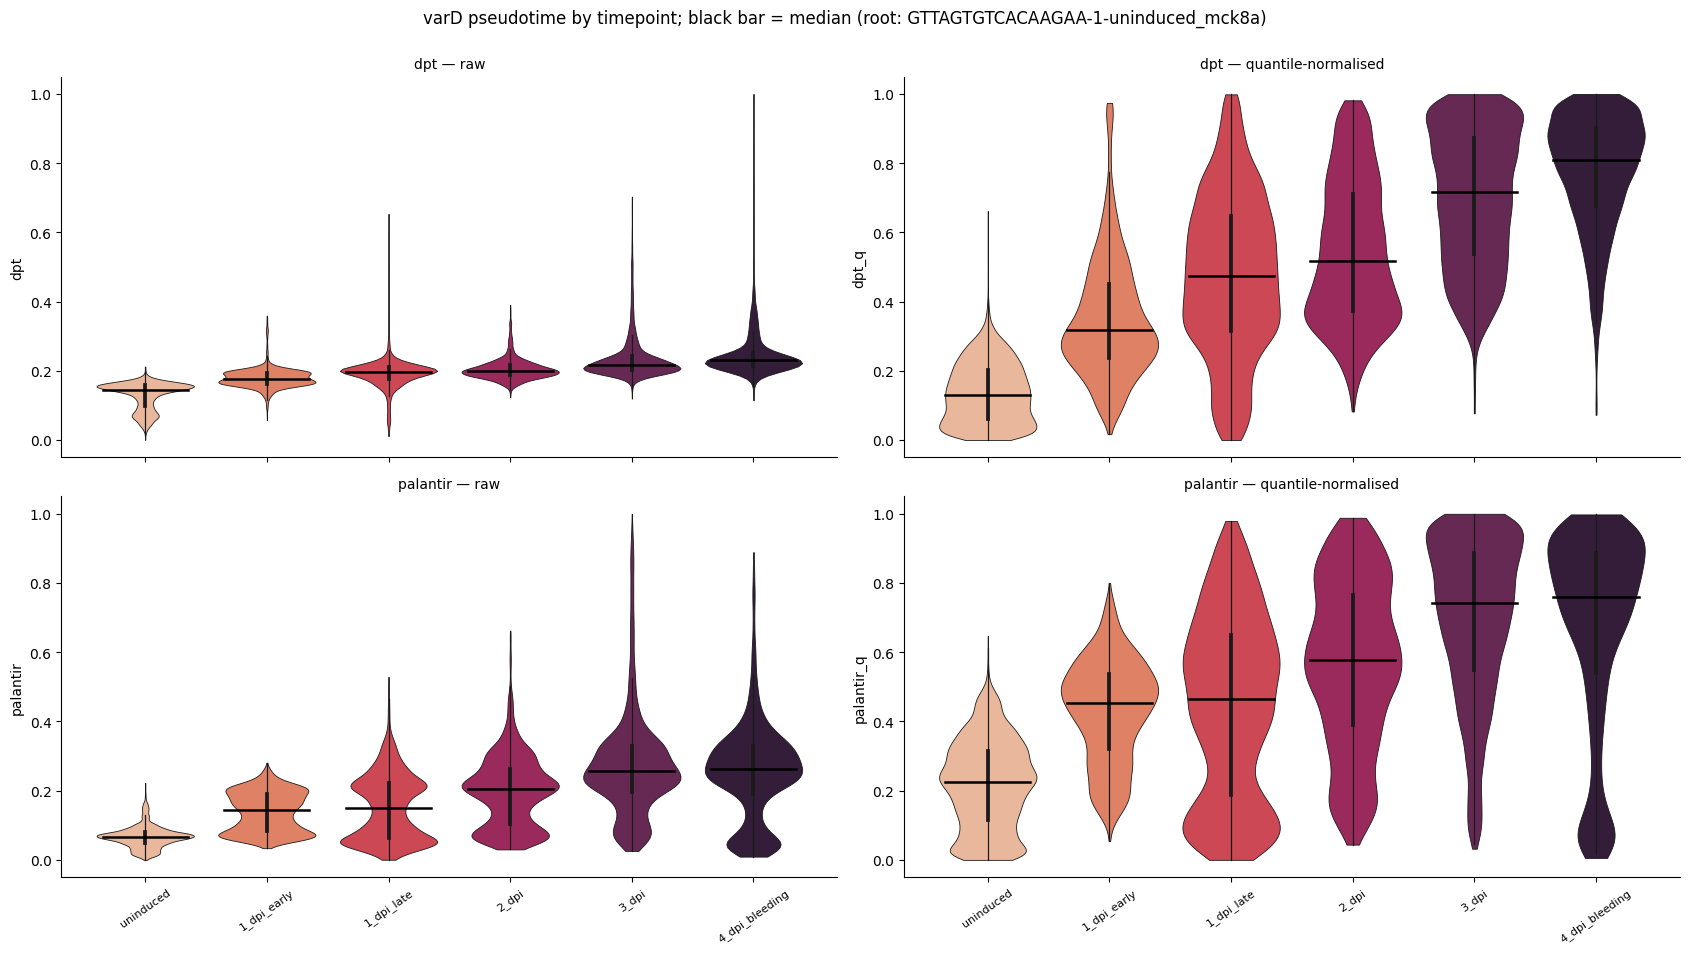

In [30]:
def violins(by="cell_subtype"):
    order = [s for s in (SUBORDER if by=="cell_subtype" else TPORDER) if s in set(O[by])]
    pal   = PAL if by=="cell_subtype" else TPAL
    fig, axes = plt.subplots(2, 2, figsize=(17, 9.5), sharex=True)
    for i, m in enumerate(("dpt","palantir")):
        for j, col in enumerate((m, f"{m}_q")):
            ax = axes[i][j]
            sns.violinplot(data=res, x=by, y=col, order=order, hue=by, hue_order=order,
                           palette=pal, legend=False, cut=0, linewidth=.6, ax=ax)
            med = res.groupby(by, observed=True)[col].median()
            for k, cat in enumerate(order): ax.plot([k-.35,k+.35],[med[cat]]*2, c="k", lw=1.8, zorder=5)
            ax.set_title(f"{m} — {'quantile-normalised' if col.endswith('_q') else 'raw'}", fontsize=10)
            ax.set_xlabel(""); ax.tick_params(axis="x", rotation=35, labelsize=8)
    fig.suptitle(f"varD pseudotime by {by}; black bar = median (root: {ROOT_BC})", y=1.0)
    fig.tight_layout(); return fig
_ = violins("cell_subtype")
_ = violins("timepoint")

print("median by timepoint, split by compartment (Palantir quantile) — the pooled column is composition-driven:")
res["compartment"] = np.where(res.cell_subtype.str.startswith("decidual"), "decidual", "fibroblast")
display(res.pivot_table(index="timepoint", columns="compartment", values="palantir_q",
                        aggfunc="median", observed=True).reindex(TPORDER).round(3))

## 10 — spatial pseudotime, raw and quantile-normalised

One row per tissue section (from 04f, `y > x - 500` splitting the two uninduced cross-sections). Raw and global-quantile columns share a colour scale across all sections so panels are comparable; the within-section column is on its own scale by construction. Cells without a QC'd coordinate are omitted.

22,191 of 40,217 cells have a coordinate | 11 sections


tissue_section,1_dpi_early_mck1__A,1_dpi_late_mck12a__A,1_dpi_late_mck12b__A,2_dpi_mck15__A,3_dpi_mck10a__A,3_dpi_mck10b__A,4_dpi_bleeding_mck11a__A,uninduced_mck8a__A,uninduced_mck8a__B,uninduced_mck8b__A,uninduced_mck8b__B
n_cells,1379,3325,1420,2008,3065,3459,3976,883,966,834,876


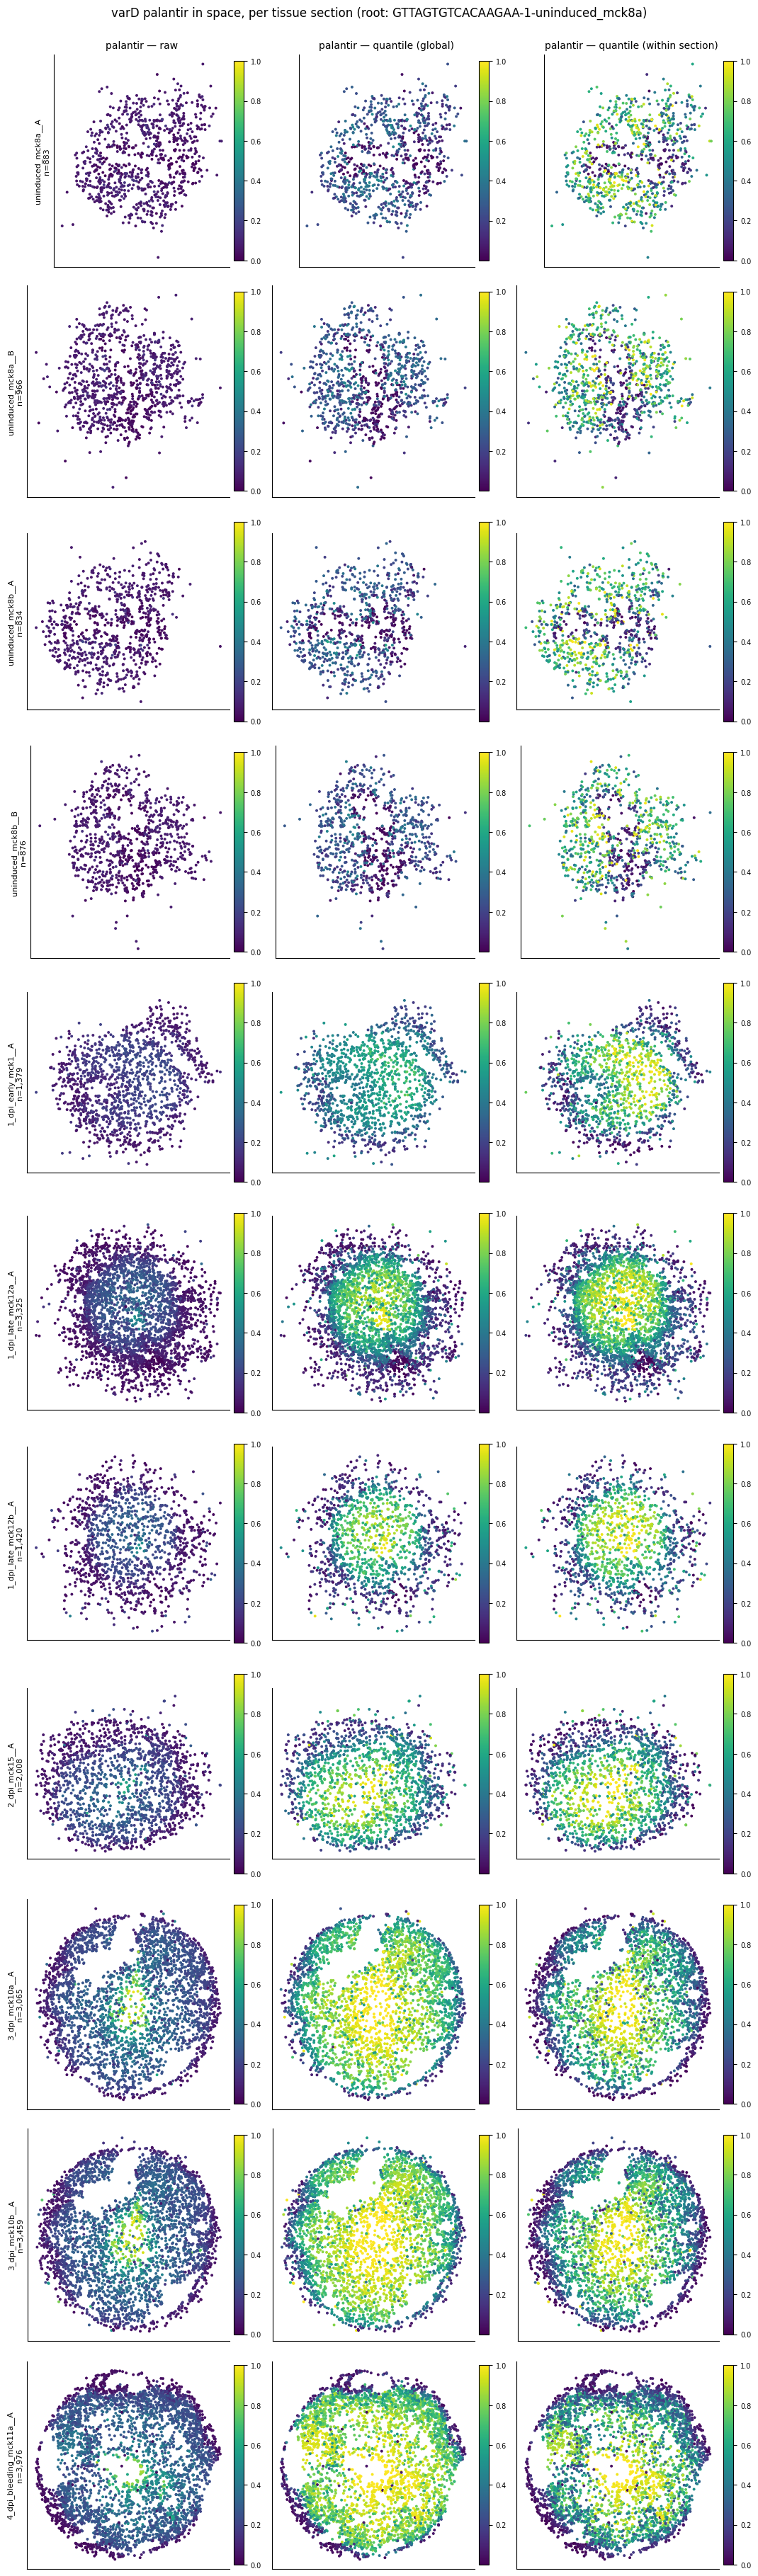

In [31]:
SP = res[np.isfinite(res.x_um) & res.tissue_section.notna()].copy()
secs = ([s for s in sorted(SP.tissue_section.unique()) if s.startswith("uninduced")] +
        [s for s in sorted(SP.tissue_section.unique()) if not s.startswith("uninduced")])
print(f"{len(SP):,} of {len(res):,} cells have a coordinate | {len(secs)} sections")
display(SP.groupby("tissue_section", observed=True).size().rename("n_cells").to_frame().T)

def spatial_panels(method="palantir", cols=("", "_q", "_qsec"), s=3.4, per=3.6):
    labs = {"":"raw", "_q":"quantile (global)", "_qsec":"quantile (within section)"}
    fig, axes = plt.subplots(len(secs), len(cols), figsize=(per*len(cols), per*len(secs)*0.92), squeeze=False)
    for i, sec in enumerate(secs):
        g = SP[SP.tissue_section == sec]
        for j, suf in enumerate(cols):
            ax = axes[i][j]; col = f"{method}{suf}"
            vmin, vmax = ((SP[col].min(), SP[col].max()) if suf != "_qsec" else (0, 1))
            sm = ax.scatter(g.x_um, g.y_um, c=g[col], s=s, cmap="viridis", vmin=vmin, vmax=vmax, rasterized=True)
            ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title(f"{method} — {labs[suf]}", fontsize=10)
            if j == 0: ax.set_ylabel(f"{sec}\nn={len(g):,}", fontsize=8)
            plt.colorbar(sm, ax=ax, fraction=.046, pad=.02).ax.tick_params(labelsize=7)
    fig.suptitle(f"varD {method} in space, per tissue section (root: {ROOT_BC})", y=1.0)
    fig.tight_layout(); return fig

_ = spatial_panels("palantir")

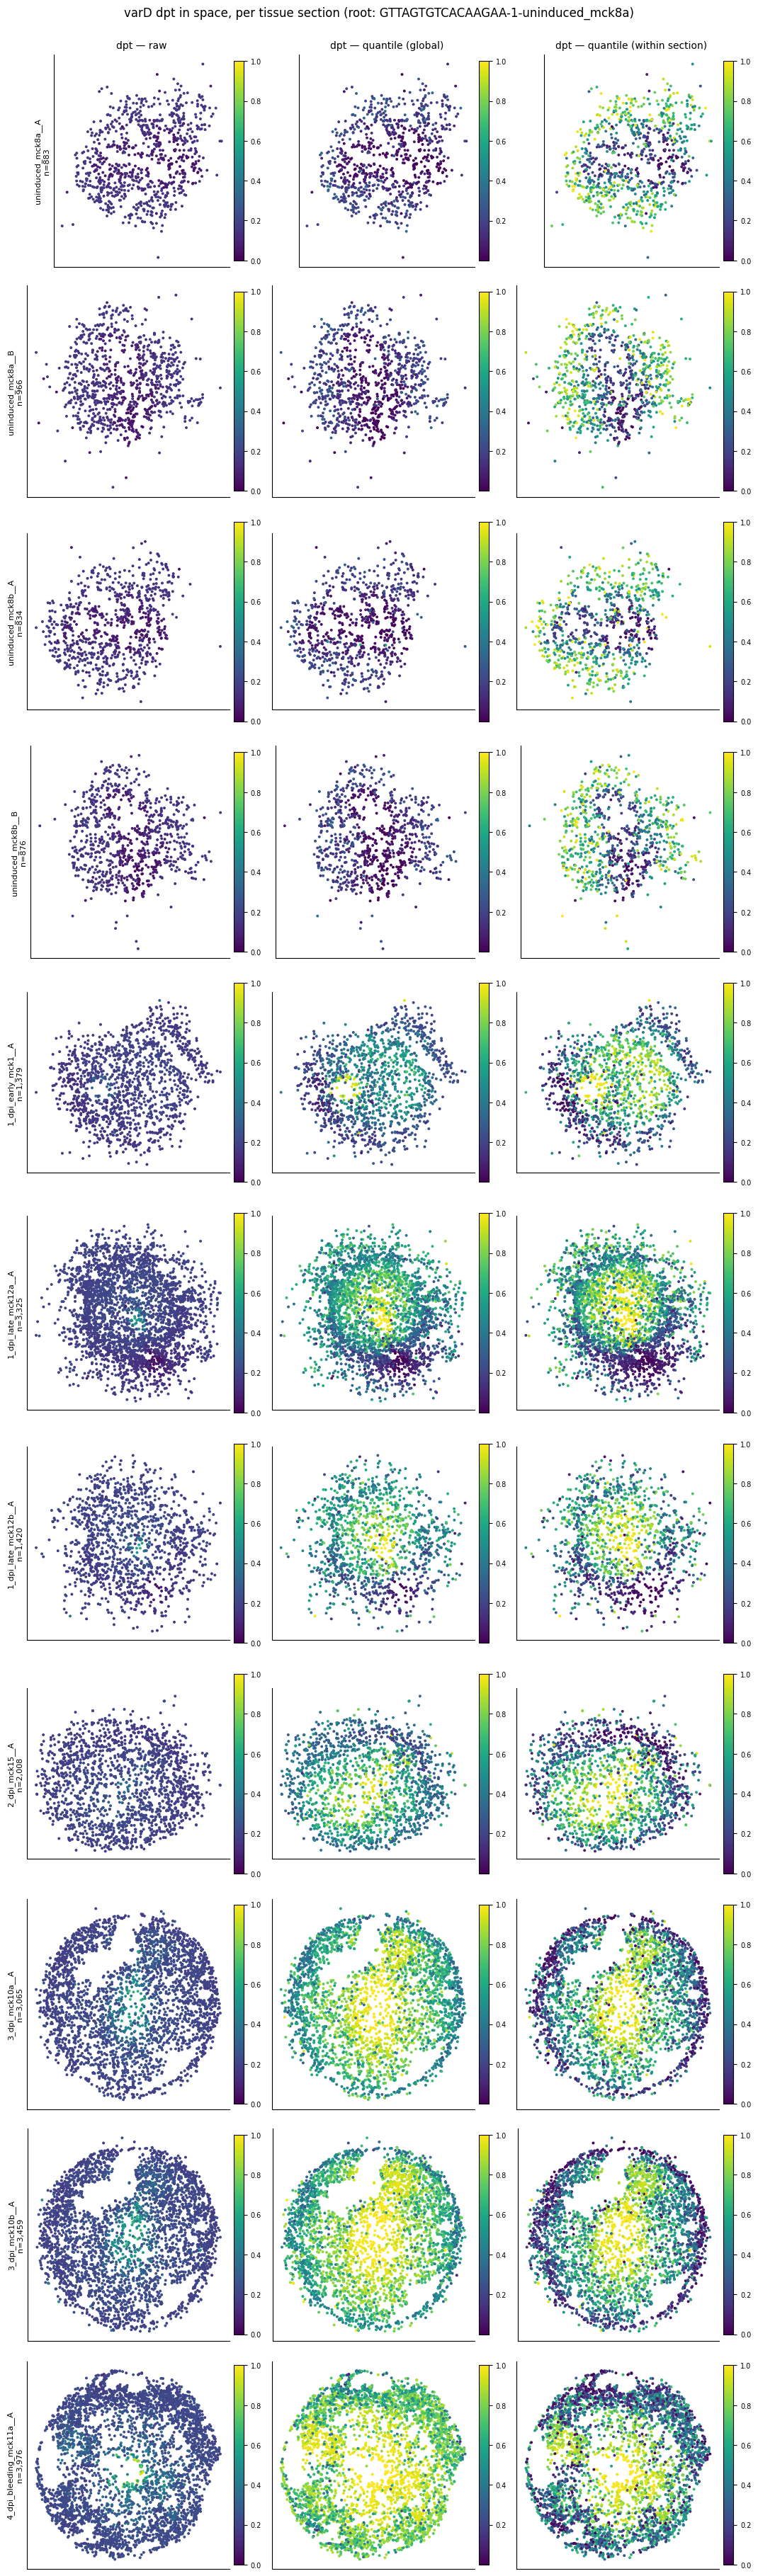

In [32]:
_ = spatial_panels("dpt")

### Pseudotime vs isodepth, per section

The spatial coordinate the rest of the project uses. Isodepth is a quantile scale already, so Spearman is the right comparison, and the quantile transform of pseudotime leaves it unchanged.

In [ ]:
with h5py.File(ISO, "r") as f:
    icols = [c for c in f["obs"].keys() if "isodepth" in c]
    iso = pd.DataFrame({c: pd.to_numeric(read_elem(f[f"obs/{c}"]), errors="coerce") for c in icols},
                       index=pd.Index(read_elem(f["obs/_index"])))
print("isodepth columns:", icols)
ICOL = "isodepth_consensus" if "isodepth_consensus" in icols else (icols[0] if icols else None)
if ICOL:
    SP["isodepth"] = iso[ICOL].reindex(SP.index).to_numpy(float)
    m = np.isfinite(SP.isodepth)
    print(f"{int(m.sum()):,} of {len(SP):,} spatial cells carry {ICOL}")
    rows = []
    for sec, g in SP[m].groupby("tissue_section", observed=True):
        if len(g) < 100: continue
        rows.append(dict(section=sec, n=len(g),
                         rho_palantir=round(float(spearmanr(g.palantir, g.isodepth).statistic),3),
                         rho_palantir_q=round(float(spearmanr(g.palantir_q, g.isodepth).statistic),3),
                         rho_dpt=round(float(spearmanr(g.dpt, g.isodepth).statistic),3)))
    IS = pd.DataFrame(rows).set_index("section"); display(IS)
    verify("quantile transform does not change the isodepth correlation",
           bool(np.allclose(IS.rho_palantir, IS.rho_palantir_q, atol=1e-3)))
    fig, axes = plt.subplots(1, min(4, len(secs)), figsize=(4.3*min(4,len(secs)), 4))
    for ax, sec in zip(np.atleast_1d(axes), secs[:4]):
        g = SP[(SP.tissue_section == sec) & m]
        ax.scatter(g.isodepth, g.palantir_q, s=2, c=[PAL[s] for s in g.cell_subtype], rasterized=True)
        ax.set_xlabel(ICOL); ax.set_ylabel("palantir (quantile)"); ax.set_title(sec, fontsize=9)
    fig.tight_layout()
else:
    print("no isodepth column found — skipping")

## 11 — save

In [ ]:
tag = (ROOT_BARCODE or f"dc{ROOT['dc']}{ROOT['side']}pct{ROOT['pct']}"
       + ("_" + ROOT["timepoint"] if "timepoint" in ROOT else "")
       + ("_" + ROOT["subtype"]   if "subtype"   in ROOT else ""))
res["root_barcode"] = ROOT_BC; res["root_desc"] = ROOT_DESC
fn = OUT/f"varD_pt_{tag}.csv"; res.to_csv(fn)
json.dump(dict(root_barcode=ROOT_BC, root_desc=ROOT_DESC, spec=(ROOT_BARCODE or ROOT), gates=GATES,
               palantir_version=palantir.__version__, use_early_cell_as_start=True,
               n_cells=int(len(res)), n_with_coords=int(len(SP)),
               checks=[{"label":l,"ok":o,"got":str(g)} for l,o,g,_ in CHECKS]),
          open(OUT/f"varD_pt_{tag}_report.json","w"), indent=1, default=str)
print("wrote", fn)
bad = [l for l,o,_,_ in CHECKS if not o]
print(f"\n{len(CHECKS)} checks | {len(bad)} FAILED" + (": " + "; ".join(bad) if bad else " — all passed"))